In [10]:
from pathlib import Path
import os, json, random, hashlib, platform, importlib.metadata, time, math
import torch_directml
from collections import defaultdict
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms as T
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Change these before starting an experiment. Use a new RUN_NAME for each run.
DATA_ROOT = None  # auto-find dataset in current folder or one folder below
RUN_NAME = 'directml_sgd_v2'
OUTPUT_BASE = Path('outputs')
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 4    # reduce to 2 if GPU/shared memory is exhausted
NUM_WORKERS = 0   # Windows notebook: load images in the main process
EPOCHS = 12
WARMUP_EPOCHS = 1
PATIENCE = 4
BACKBONE_LR = 1e-3
HEAD_LR = 1e-2
WEIGHT_DECAY = 1e-4
WEIGHTS_PATH = None  # optional local torchvision state_dict (.pth)
SMOKE_TEST = False    # two epochs / two batches each: tests head-only AND fine-tuning

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch_directml.device()
AMP = False  # DirectML: use full float32; no autocast or GradScaler
print('Device:', DEVICE, '| torch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('DirectML adapter:', torch_directml.device_name(0))
OUT = OUTPUT_BASE / RUN_NAME
OUT.mkdir(parents=True, exist_ok=False)  # protects earlier experimental evidence
config = {k: globals()[k] for k in ['RUN_NAME','SEED','IMAGE_SIZE','BATCH_SIZE','NUM_WORKERS','EPOCHS','WARMUP_EPOCHS','PATIENCE','BACKBONE_LR','HEAD_LR','WEIGHT_DECAY','SMOKE_TEST']}
config.update(optimizer='SGD', momentum=0.9, freeze_bn_statistics=True, device=str(DEVICE))
config['weights'] = str(WEIGHTS_PATH or 'EfficientNet_B0_Weights.DEFAULT')
(OUT/'config.json').write_text(json.dumps(config, indent=2))
versions = {p: importlib.metadata.version(p) for p in ['torch','torchvision','torch-directml','numpy','pandas','Pillow','scikit-learn','matplotlib','tqdm']}
(OUT/'environment.json').write_text(json.dumps({'python':platform.python_version(), **versions}, indent=2))


Device: privateuseone:0 | torch: 2.4.1+cpu | torchvision: 0.19.1+cpu
DirectML adapter: AMD Radeon(TM) Graphics 


246

Root: c:\Users\Danie\OneDrive\Documents\GitHub\Kaggle-Competition-2026\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch (1) | training rows: 63660 | test IDs: 29443
Exact classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']


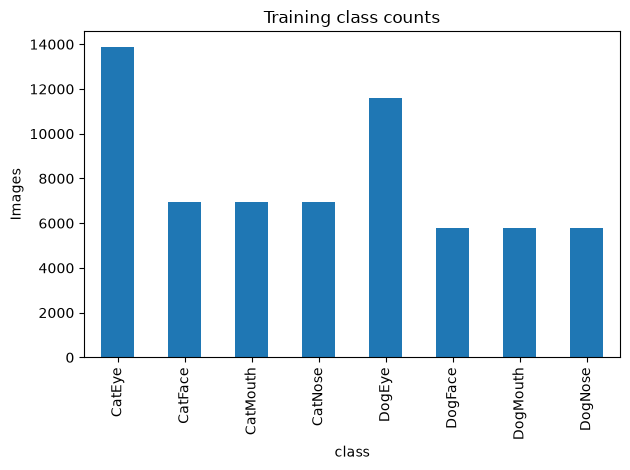

In [11]:
if DATA_ROOT is None:
    search_folders = [Path.cwd()] + [p for p in Path.cwd().iterdir() if p.is_dir()]
    candidates = sorted({p for p in search_folders if (p/'sample_submission.csv').exists()
                         and ((p/'train_labels.csv').exists() or (p/'train.csv').exists())})
    if len(candidates) != 1:
        raise ValueError(f'Set DATA_ROOT explicitly. Found candidate folders: {candidates}')
    DATA_ROOT = candidates[0]
DATA_ROOT = Path(DATA_ROOT)
label_file = DATA_ROOT/'train_labels.csv'
if not label_file.exists(): label_file = DATA_ROOT/'train.csv'
labels = pd.read_csv(label_file, dtype=str, keep_default_na=False)
sample = pd.read_csv(DATA_ROOT/'sample_submission.csv', dtype=str, keep_default_na=False)
for name, frame in [('training', labels), ('submission template', sample)]:
    if not {'image_id','class'}.issubset(frame.columns):
        raise ValueError(f'{name} columns are {list(frame.columns)}; expected image_id,class.')
    if frame.image_id.eq('').any() or frame.image_id.duplicated().any():
        raise ValueError(f'Empty or duplicated IDs in {name}.')
if labels['class'].eq('').any(): raise ValueError('Empty training labels.')
classes = sorted(labels['class'].unique().tolist())
assert len(classes) == 8, classes
assert len(sample) == 29443, f'Expected 29,443 test IDs; found {len(sample)}'
class_to_idx = {label:i for i,label in enumerate(classes)}
(OUT/'class_mapping.json').write_text(json.dumps(class_to_idx, indent=2))

def numeric_key(value):
    stem = Path(str(value)).stem
    return str(int(stem)) if stem.isdigit() else None

def resolve_images(folder, ids):
    files = sorted(p for p in folder.rglob('*') if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp'})
    if not files: raise FileNotFoundError(f'No images in {folder}')
    lookups = [defaultdict(list) for _ in range(4)]
    for p in files:
        keys = [p.relative_to(folder).as_posix(), p.name, p.stem, numeric_key(p.name)]
        for table, key in zip(lookups, keys):
            if key is not None: table[key].append(p)
    resolved=[]
    for value in ids:
        keys=[str(value), Path(value).name, Path(value).stem, numeric_key(value)]
        matches=[]
        for table,key in zip(lookups,keys):
            matches=table.get(key, [])
            if matches: break
        if len(matches)!=1: raise ValueError(f'{value}: {len(matches)} matching files in {folder}')
        resolved.append(str(matches[0]))
    if len(set(resolved)) != len(resolved): raise ValueError('Multiple IDs resolve to the same file.')
    return resolved

labels['path'] = resolve_images(DATA_ROOT/'train', labels.image_id)
labels['target'] = labels['class'].map(class_to_idx)
print('Root:', DATA_ROOT, '| training rows:',len(labels),'| test IDs:',len(sample))
print('Exact classes:', classes)
labels['class'].value_counts().reindex(classes).rename('count').to_csv(OUT/'class_counts.csv')
labels['class'].value_counts().reindex(classes).plot.bar(title='Training class counts', ylabel='Images')
plt.tight_layout(); plt.savefig(OUT/'class_counts.png', dpi=150); plt.show()


Audit training images:   0%|          | 0/63660 [00:00<?, ?it/s]

Audit training images: 100%|██████████| 63660/63660 [02:54<00:00, 363.96it/s]


Corrupt rows excluded: 0
              width        height
count  63660.000000  63660.000000
mean     113.095209    109.737857
std       98.491801    101.911146
min        4.000000      4.000000
25%       54.000000     50.000000
50%       84.000000     80.000000
75%      138.000000    130.000000
max     2219.000000   2219.000000
split     train  validation
class                      
CatEye    11107        2777
CatFace    5553        1389
CatMouth   5554        1388
CatNose    5554        1388
DogEye     9264        2316
DogFace    4632        1158
DogMouth   4632        1158
DogNose    4632        1158


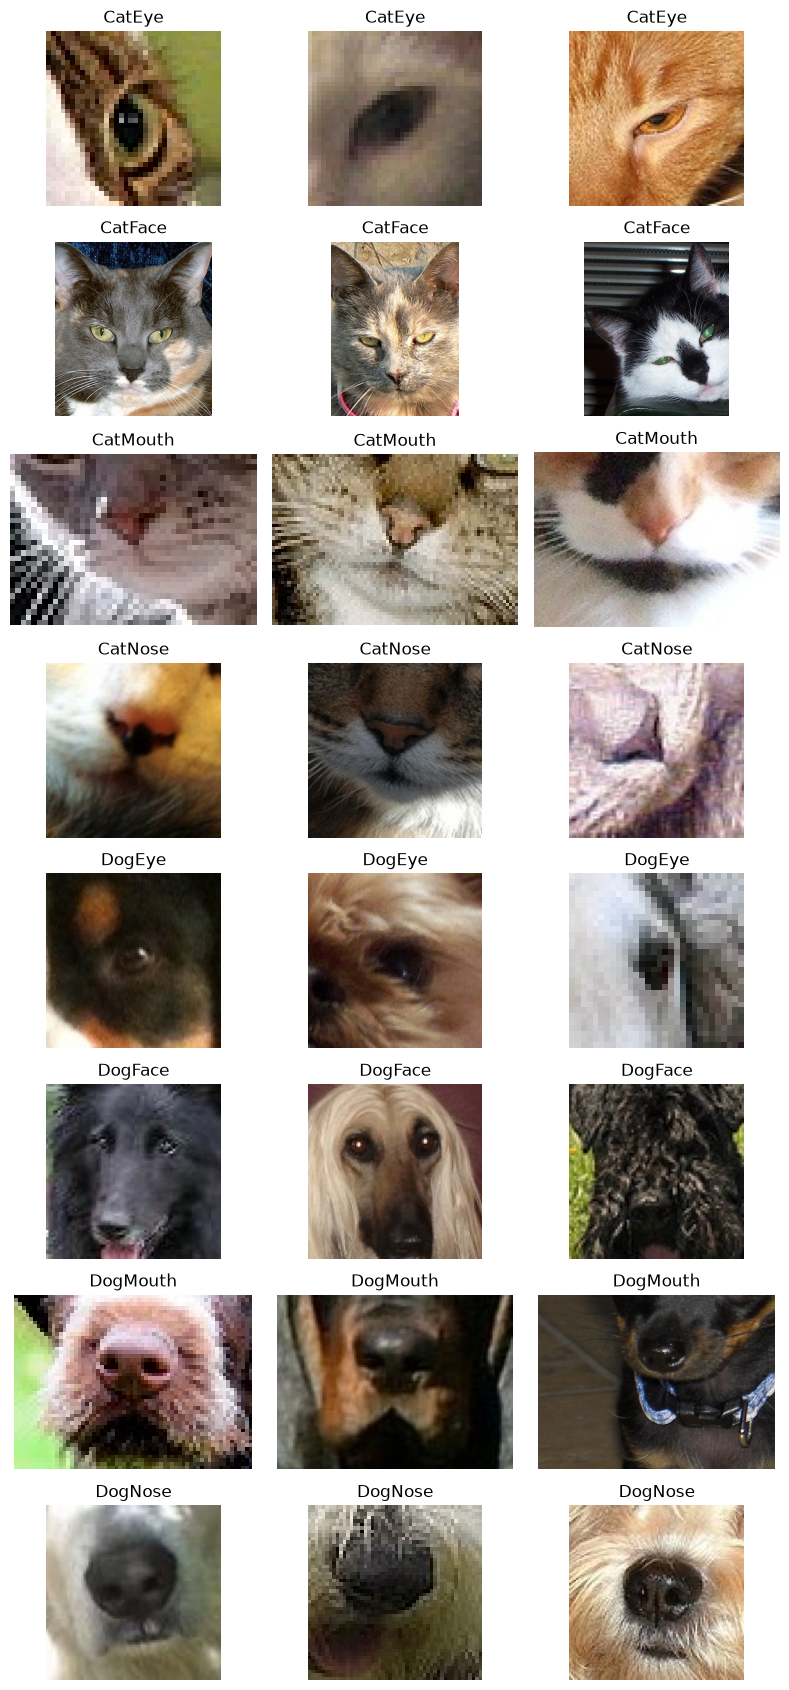

In [12]:
audit=[]
for row in tqdm(labels.itertuples(), total=len(labels), desc='Audit training images'):
    record={'image_id':row.image_id, 'error':''}
    try:
        with Image.open(row.path) as raw:
            im=ImageOps.exif_transpose(raw).convert('RGB')
            im.load()
            record.update(width=im.width, height=im.height,
                          image_hash=hashlib.sha256(str(im.size).encode()+im.tobytes()).hexdigest())
    except Exception as exc: record['error']=str(exc)
    audit.append(record)
audit=pd.DataFrame(audit)
audit.to_csv(OUT/'training_image_audit.csv', index=False)
labels=labels.merge(audit, on='image_id', validate='one_to_one')
print('Corrupt rows excluded:', labels.error.ne('').sum())
labels=labels[labels.error.eq('')].reset_index(drop=True)
assert set(labels['class']) == set(classes), 'A class has no valid images.'
conflicts=labels.groupby('image_hash')['class'].nunique()
if conflicts.gt(1).any():
    labels[labels.image_hash.isin(conflicts[conflicts.gt(1)].index)].to_csv(OUT/'conflicting_labels.csv',index=False)
    raise ValueError('Conflicting labels for identical images; inspect conflicting_labels.csv.')
labels[labels.image_hash.duplicated(keep=False)].to_csv(OUT/'exact_duplicates.csv', index=False)
print(labels[['width','height']].describe())
if labels.groupby('class').image_hash.nunique().min() < 5:
    raise ValueError('Need at least five distinct image groups per class for this split.')
splitter=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, val_idx=next(splitter.split(labels, labels.target, groups=labels.image_hash))
train_df=labels.iloc[train_idx].reset_index(drop=True)
val_df=labels.iloc[val_idx].reset_index(drop=True)
assert not set(train_df.image_hash) & set(val_df.image_hash)
assert set(train_df['class']) == set(val_df['class']) == set(classes)
labels['split']='train'; labels.loc[val_idx,'split']='validation'
labels.to_csv(OUT/'split_manifest.csv', index=False)
print(pd.crosstab(labels['class'],labels.split))
fig,axes=plt.subplots(8,3,figsize=(8,17))
for i, name in enumerate(classes):
    examples=labels[labels['class'].eq(name)].sample(3,random_state=SEED,replace=True)
    for ax,path in zip(axes[i],examples.path):
        with Image.open(path) as raw: ax.imshow(ImageOps.exif_transpose(raw).convert('RGB'))
        ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.savefig(OUT/'training_samples.png',dpi=140); plt.show()


In [13]:
mean=(0.485,0.456,0.406); std=(0.229,0.224,0.225)
eval_tf=T.Compose([T.Resize((IMAGE_SIZE,IMAGE_SIZE)),T.ToTensor(),T.Normalize(mean,std)])
train_tf=T.Compose([T.Resize((IMAGE_SIZE,IMAGE_SIZE)),T.RandomHorizontalFlip(),
                    T.RandomRotation(10),T.ColorJitter(brightness=0.15,contrast=0.15,saturation=0.1),
                    T.ToTensor(),T.Normalize(mean,std)])
class FeatureDataset(Dataset):
    def __init__(self, frame, transform): self.frame=frame.reset_index(drop=True); self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self,index):
        row=self.frame.iloc[index]
        with Image.open(row.path) as raw: im=ImageOps.exif_transpose(raw).convert('RGB')
        return self.transform(im), int(row.target) if 'target' in self.frame.columns else -1

def seed_worker(worker_id):
    seed=torch.initial_seed() % 2**32
    np.random.seed(seed); random.seed(seed)

def loader(frame, transform, shuffle=False):
    return DataLoader(FeatureDataset(frame,transform),batch_size=BATCH_SIZE,shuffle=shuffle,
                      num_workers=NUM_WORKERS,pin_memory=False,worker_init_fn=seed_worker,
                      generator=torch.Generator().manual_seed(SEED))
train_loader=loader(train_df,train_tf,True)
val_loader=loader(val_df,eval_tf)
if WEIGHTS_PATH:
    model=efficientnet_b0(weights=None)
    model.load_state_dict(torch.load(WEIGHTS_PATH,map_location='cpu',weights_only=True))
else:
    model=efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
model.classifier[1]=nn.Linear(model.classifier[1].in_features,len(classes))
model=model.to(DEVICE)
(OUT/'architecture.txt').write_text(str(model))
criterion=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD([{'params':model.features.parameters(),'lr':BACKBONE_LR},
                           {'params':model.classifier.parameters(),'lr':HEAD_LR}],
                          momentum=0.9, weight_decay=WEIGHT_DECAY, foreach=False)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.5,patience=1)



In [14]:
def run_epoch(data_loader, training=False, freeze_backbone=False):
    model.train(training)
    if training:
        if freeze_backbone:
            model.features.eval()
        else:
            # Keep pretrained running statistics with a small batch size.
            for module in model.modules():
                if isinstance(module, nn.modules.batchnorm._BatchNorm):
                    module.eval()
    total_loss = correct = count = 0
    all_probs = []; all_targets = []
    start = time.perf_counter()
    with torch.set_grad_enabled(training):
        for batch_i, (images, targets_cpu) in enumerate(tqdm(data_loader, leave=False)):
            images = images.to(DEVICE)
            targets = targets_cpu.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, targets)
            loss_value = loss.detach().cpu().item()
            if not math.isfinite(loss_value):
                raise RuntimeError('Non-finite loss; stop and inspect the inputs and learning rate.')
            if training:
                loss.backward()
                optimizer.step()
            # Small metric tensors go to CPU; no unsupported GPU metric operations.
            logits_cpu = logits.detach().cpu()
            total_loss += loss_value * len(targets_cpu)
            correct += (logits_cpu.argmax(1) == targets_cpu).sum().item()
            count += len(targets_cpu)
            if not training:
                all_probs.append(logits_cpu.softmax(1).numpy())
                all_targets.append(targets_cpu.numpy())
            if SMOKE_TEST and batch_i >= 1:
                break
    elapsed = time.perf_counter() - start
    print(f"{'Train' if training else 'Validation'}: {count} images, {elapsed:.1f} s ({count/elapsed:.1f} images/s)")
    return (total_loss/count, correct/count,
            np.concatenate(all_probs) if all_probs else None,
            np.concatenate(all_targets) if all_targets else None)

history = []; best_accuracy = -1.; best_loss = float('inf'); stale = 0
for epoch in range(1, (2 if SMOKE_TEST else EPOCHS) + 1):
    epoch_start = time.perf_counter()
    freeze = epoch <= WARMUP_EPOCHS
    for p in model.features.parameters():
        p.requires_grad_(not freeze)
    train_loss, train_acc, _, _ = run_epoch(train_loader, True, freeze)
    val_loss, val_acc, _, _ = run_epoch(val_loader)
    history.append({'epoch': epoch, 'train_loss': train_loss, 'train_accuracy': train_acc,
                    'val_loss': val_loss, 'val_accuracy': val_acc,
                    'backbone_lr': optimizer.param_groups[0]['lr'],
                    'head_lr': optimizer.param_groups[1]['lr'],
                    'seconds': time.perf_counter() - epoch_start})
    pd.DataFrame(history).to_csv(OUT/'history.csv', index=False)
    print(f'Epoch {epoch:02d}: train loss {train_loss:.4f}, acc {train_acc:.4f} | val loss {val_loss:.4f}, acc {val_acc:.4f}')
    improved = val_acc > best_accuracy or (val_acc == best_accuracy and val_loss < best_loss)
    if improved:
        best_accuracy, best_loss, stale = val_acc, val_loss, 0
        # CPU checkpoint tensors avoid DirectML storage-serialization issues.
        torch.save({'state_dict': {k: v.detach().cpu() for k,v in model.state_dict().items()},
                    'classes': classes, 'config': config, 'epoch': epoch,
                    'val_accuracy': val_acc, 'val_loss': val_loss}, OUT/'best_model.pt')
    else:
        stale += 1
    scheduler.step(val_loss)
    if stale >= PATIENCE:
        print('Early stopping.'); break


Train: 50928 images, 1677.9 s (30.4 images/s)


Validation: 12732 images, 302.7 s (42.1 images/s)
Epoch 01: train loss 0.5141, acc 0.8733 | val loss 0.4386, acc 0.8863


RuntimeError: Non-finite loss; stop and inspect the inputs and learning rate.

In [15]:
checkpoint_path = OUT / "best_model.pt"
assert checkpoint_path.exists(), f"Checkpoint missing: {checkpoint_path}"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)

assert checkpoint["classes"] == classes

model.load_state_dict(checkpoint["state_dict"])
model.eval()

print("Restored epoch:", checkpoint["epoch"])
print(f"Validation accuracy: {checkpoint['val_accuracy']:.2%}")
print("Output folder:", OUT)

Restored epoch: 1
Validation accuracy: 88.63%
Output folder: outputs\directml_sgd_v2


Validation: 12732 images, 296.0 s (43.0 images/s)


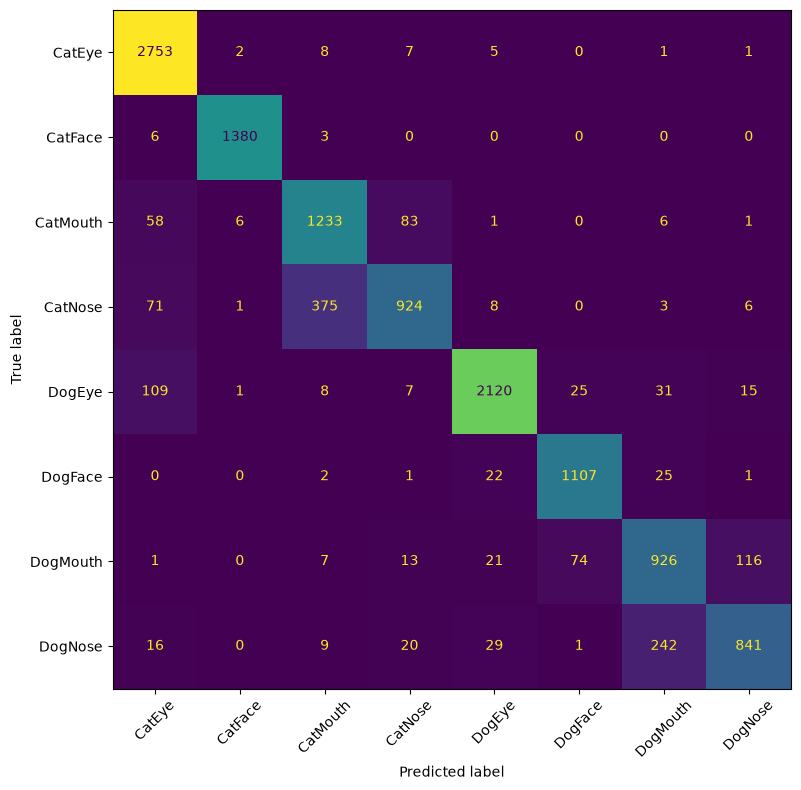

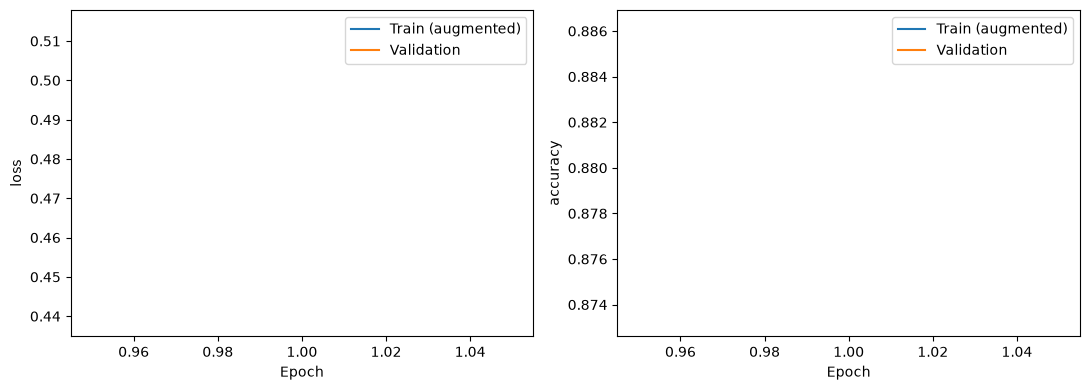

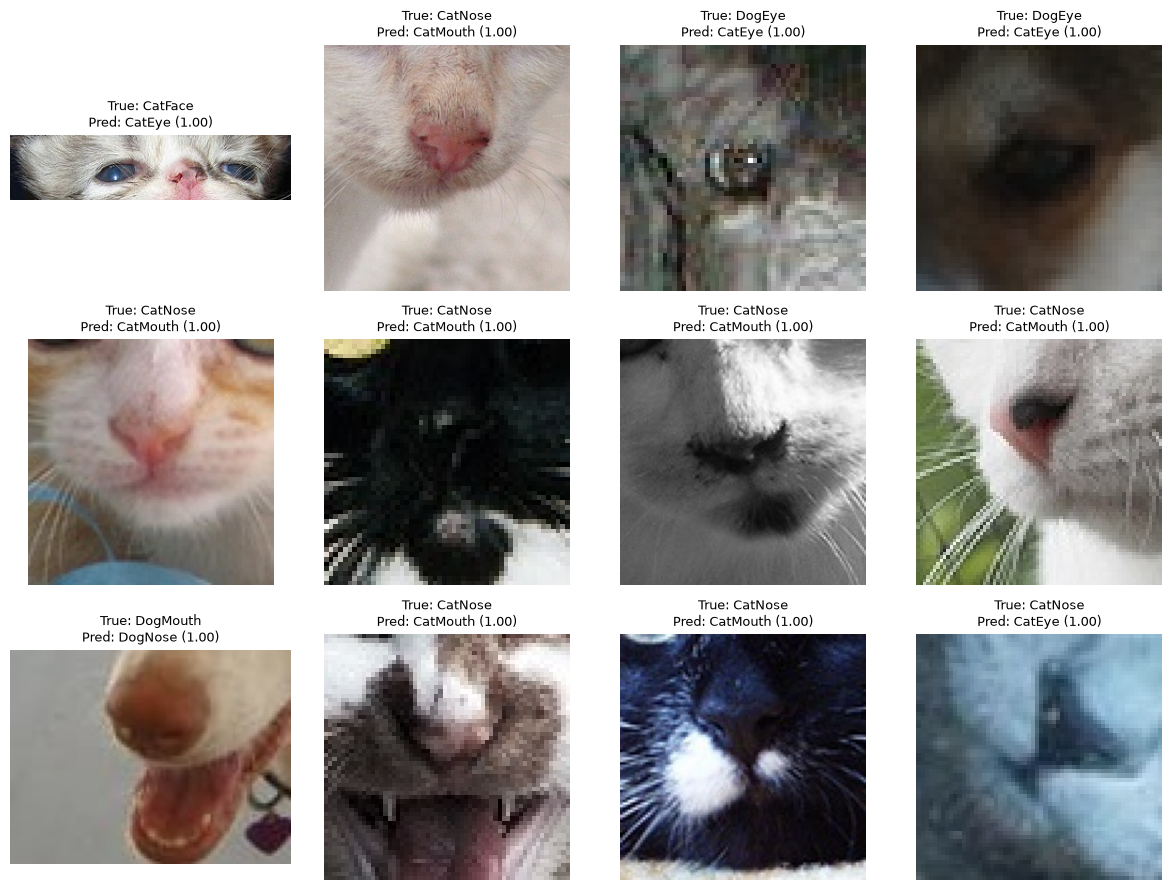

Validation accuracy: 0.8862708136977694 | loss: 0.43861365832340937


In [16]:
checkpoint=torch.load(OUT/'best_model.pt',map_location='cpu',weights_only=True)
model.load_state_dict(checkpoint['state_dict'])
val_loss,val_acc,probs,truth=run_epoch(val_loader)
pred=probs.argmax(1)
report=classification_report(truth,pred,labels=list(range(8)),target_names=classes,output_dict=True,zero_division=0)
pd.DataFrame(report).transpose().to_csv(OUT/'classification_metrics.csv')
(OUT/'validation_metrics.json').write_text(json.dumps({'loss':val_loss,'accuracy':val_acc,'checkpoint_epoch':checkpoint['epoch'],'smoke_test':SMOKE_TEST},indent=2))
results=val_df.iloc[:len(pred)][['image_id','path','class']].copy()
results['prediction']=[classes[i] for i in pred]; results['confidence']=probs.max(1)
results.to_csv(OUT/'validation_predictions.csv',index=False)
np.save(OUT/'validation_probabilities.npy',probs)
cm=confusion_matrix(truth,pred,labels=list(range(8)))
pd.DataFrame(cm,index=classes,columns=classes).to_csv(OUT/'confusion_matrix.csv')
fig,ax=plt.subplots(figsize=(9,8))
ConfusionMatrixDisplay(cm,display_labels=classes).plot(ax=ax,xticks_rotation=45,colorbar=False)
plt.tight_layout(); plt.savefig(OUT/'confusion_matrix.png',dpi=150); plt.show()
h=pd.DataFrame(history)
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,metric in zip(axes,['loss','accuracy']):
    ax.plot(h.epoch,h['train_'+metric],label='Train (augmented)')
    ax.plot(h.epoch,h['val_'+metric],label='Validation')
    ax.set(xlabel='Epoch',ylabel=metric); ax.legend()
plt.tight_layout(); plt.savefig(OUT/'learning_curves.png',dpi=150); plt.show()
errors=results[results['class']!=results.prediction].sort_values('confidence',ascending=False)
errors.to_csv(OUT/'validation_errors.csv',index=False)
if len(errors):
    fig,axes=plt.subplots(3,4,figsize=(12,9))
    for ax in axes.flat: ax.axis('off')
    for ax,row in zip(axes.flat,errors.head(12).itertuples()):
        with Image.open(row.path) as raw: ax.imshow(ImageOps.exif_transpose(raw).convert('RGB'))
        ax.set_title(f'True: {row[3]}\nPred: {row.prediction} ({row.confidence:.2f})',fontsize=9)
    plt.tight_layout(); plt.savefig(OUT/'validation_error_examples.png',dpi=150); plt.show()
print('Validation accuracy:',val_acc,'| loss:',val_loss)


In [ ]:
if SMOKE_TEST:
    print('Smoke test finished. No submission generated. Restart with SMOKE_TEST=False and a NEW RUN_NAME for full training.')
else:
    test_df=sample[['image_id']].copy()
    test_df['path']=resolve_images(DATA_ROOT/'test',test_df.image_id)
    test_loader=loader(test_df,eval_tf)
    model.eval(); chunks=[]
    with torch.inference_mode():
        for images,_ in tqdm(test_loader,desc='Predict test'):
            logits=model(images.to(DEVICE))
            chunks.append(logits.cpu().softmax(1).numpy())
    test_probs=np.concatenate(chunks)
    assert np.isfinite(test_probs).all()
    submission=sample[['image_id','class']].copy()
    submission['class']=[classes[i] for i in test_probs.argmax(1)]
    assert len(submission)==len(sample)==29443
    assert submission.image_id.tolist()==sample.image_id.tolist()
    assert submission.image_id.is_unique and submission['class'].isin(classes).all()
    submission.to_csv(OUT/'submission.csv',index=False)
    check=pd.read_csv(OUT/'submission.csv',dtype=str,keep_default_na=False)
    assert check.equals(submission)
    np.save(OUT/'test_probabilities.npy',test_probs)
    print('Submission saved:',OUT/'submission.csv')
    print(submission.head())


Smoke test finished. No submission generated. Restart with SMOKE_TEST=False and a NEW RUN_NAME for full training.


In [1]:
submission_path = OUT / "submission.csv"

print("Location:", submission_path.resolve())
print("File exists:", submission_path.exists())

if submission_path.exists():
    submission = pd.read_csv(submission_path, dtype=str)
    print("Prediction rows:", len(submission))
    display(submission.head())

NameError: name 'OUT' is not defined

In [3]:
from pathlib import Path
from collections import defaultdict

import pandas as pd
import torch
import torch_directml
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.models import efficientnet_b0
from PIL import Image, ImageOps
from tqdm import tqdm

# Locate the saved run.
OUT = Path("outputs/directml_sgd_v2").resolve()
checkpoint_path = OUT / "best_model.pt"

assert checkpoint_path.exists(), (
    f"Cannot find {checkpoint_path}\n"
    "Set OUT to the full path of your directml_sgd_v2 folder."
)

# Locate the competition dataset.
folders = [Path.cwd()] + [
    p for p in Path.cwd().iterdir() if p.is_dir()
]
candidates = [
    p for p in folders
    if (p / "sample_submission.csv").exists()
    and (p / "test").is_dir()
]

assert len(candidates) == 1, (
    f"Expected one dataset folder, found: {candidates}"
)
DATA_ROOT = candidates[0]

sample = pd.read_csv(
    DATA_ROOT / "sample_submission.csv",
    dtype=str,
    keep_default_na=False,
)
assert list(sample.columns) == ["image_id", "class"]
assert len(sample) == 29443
assert sample["image_id"].is_unique
assert sample["image_id"].ne("").all()

# Load the trained weights and original class order.
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False,
)
classes = checkpoint["classes"]
assert len(classes) == 8

image_size = int(checkpoint["config"].get("IMAGE_SIZE", 224))
device = torch_directml.device()

model = efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, len(classes)
)
model.load_state_dict(checkpoint["state_dict"])
model = model.to(device)
model.eval()

print("Loaded epoch:", checkpoint["epoch"])
print(f"Saved validation accuracy: {checkpoint['val_accuracy']:.2%}")
print("GPU:", torch_directml.device_name(0))

# Match template IDs to filenames, including zero-padded filenames.
def numeric_key(value):
    stem = Path(str(value)).stem
    return str(int(stem)) if stem.isdigit() else None

test_folder = DATA_ROOT / "test"
files = sorted(
    p for p in test_folder.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
)

lookups = [defaultdict(list) for _ in range(4)]
for path in files:
    keys = [
        path.relative_to(test_folder).as_posix(),
        path.name,
        path.stem,
        numeric_key(path.name),
    ]
    for table, key in zip(lookups, keys):
        if key is not None:
            table[key].append(path)

test_paths = []
for image_id in sample["image_id"]:
    keys = [
        image_id,
        Path(image_id).name,
        Path(image_id).stem,
        numeric_key(image_id),
    ]
    matches = []
    for table, key in zip(lookups, keys):
        matches = table.get(key, [])
        if matches:
            break
    if len(matches) != 1:
        raise ValueError(
            f"Image ID {image_id}: found {len(matches)} matching files."
        )
    test_paths.append(matches[0])

assert len(set(test_paths)) == len(test_paths)

transform = T.Compose([
    T.Resize((image_size, image_size)),
    T.ToTensor(),
    T.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
])

class TestImages(Dataset):
    def __len__(self):
        return len(test_paths)

    def __getitem__(self, index):
        with Image.open(test_paths[index]) as raw:
            image = ImageOps.exif_transpose(raw).convert("RGB")
        return transform(image)

test_loader = DataLoader(
    TestImages(),
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
)

# Predict in exactly the same order as the submission template.
predictions = []

with torch.no_grad():
    for images in tqdm(test_loader, desc="Predicting test images"):
        logits = model(images.to(device)).cpu()
        if not torch.isfinite(logits).all().item():
            raise RuntimeError("Non-finite predictions; CSV was not saved.")
        predictions.extend(logits.argmax(dim=1).tolist())

submission = sample[["image_id", "class"]].copy()
submission["class"] = [classes[index] for index in predictions]

assert len(submission) == 29443
assert submission["image_id"].tolist() == sample["image_id"].tolist()
assert submission["class"].isin(classes).all()

submission_path = OUT / "submission.csv"
submission.to_csv(submission_path, index=False)

check = pd.read_csv(submission_path, dtype=str, keep_default_na=False)
assert check.equals(submission)

print("\nSubmission saved:", submission_path)
print("Prediction rows:", len(submission))
display(submission.head())

Loaded epoch: 1
Saved validation accuracy: 88.63%
GPU: AMD Radeon(TM) Graphics 


Predicting test images: 100%|██████████| 7361/7361 [17:10<00:00,  7.15it/s] 


Submission saved: C:\Users\Danie\OneDrive\Documents\GitHub\Kaggle-Competition-2026\outputs\directml_sgd_v2\submission.csv
Prediction rows: 29443


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth
